# Triaje por especialista — informe (reto3, IA2)

**Caso de uso:** una persona escribe sus síntomas; el sistema responde a qué especialista debería acudir.
**Tesis a contrastar con datos:** un agente único con guardrail determinista iguala o supera al router multiagente en calidad, con menos latencia y menos coordinación.

## 1. Problema y alcance
- **Dentro:** catálogo cerrado de 15 especialidades (incluye `urgencias` y `medicina_general`), guardrail de signos de alarma, configuraciones A/B/C comparables, métricas de calidad, costo, latencia, robustez y coordinación, app Streamlit local.
- **Fuera:** diagnóstico, prescripción/dosis, interpretación de exámenes, historia clínica, integración con EPS, validación clínica (el dataset es **sintético**).

Este notebook solo narra y grafica: lee resultados precalculados (`data/resultados.csv`, `data/trazas.csv`).

In [1]:
import sys, subprocess, warnings
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from triage.metricas import resumen, METAS, cumple
from triage.datos import VINETAS
from triage.guardia import evaluar
from triage.catalogo import catalogo_comprimido

REPETIR = False  # True -> relanza la evaluacion con el CLI (lento; requiere Ollama)
if REPETIR:
    subprocess.run([sys.executable, "-m", "triage.cli", "eval", "--configs", "A", "B", "C", "--reps", "2", "--reps-c", "1"], check=True, cwd=RAIZ)

real = RAIZ / "data" / "resultados.csv"
dry = RAIZ / "data" / "dryrun" / "resultados.csv"
DIR = real.parent if real.exists() else dry.parent
df = pd.read_csv(DIR / "resultados.csv")
trazas = pd.read_csv(DIR / "trazas.csv")
SIMULADO = bool(df["simulado"].astype(bool).any())
if SIMULADO:
    print("⚠️  DATOS SIMULADOS (ChatSimulado, --dry-run): sirven para validar el pipeline, NO son evidencia.")
    print("   Latencias, aciertos y conclusiones de abajo no se pueden citar. Ejecuta `triage eval` con Ollama.")
else:
    print("Datos reales de", DIR)
print(df.groupby("config").size().rename("filas por config").to_frame().T)

⚠️  DATOS SIMULADOS (ChatSimulado, --dry-run): sirven para validar el pipeline, NO son evidencia.
   Latencias, aciertos y conclusiones de abajo no se pueden citar. Ejecuta `triage eval` con Ollama.
config             A   B   C
filas por config  60  60  30


## 2. Patrón elegido y alternativas descartadas

```
texto libre
  -> [A0] Guardia de signos de alarma (reglas, 0 tokens) --alarma--> Urgencias (plantilla, 0 tokens)
  -> [A1] Triador (LLM, JSON, Enum cerrado)                          <- config A (producción)
  -> [A4] Router -> [A5] Especialista (opc.) -> [A3] Verificador     <- configs B / C
  -> [A2] Presentador (plantilla)
```
**Router con guardrail determinista:** la salida es una etiqueta; el enrutamiento *es* el producto.
**Descartados:** orquestador–trabajadores (no hay subtareas independientes), evaluador–optimizador en producción (no hay borrador que iterar), pipeline fijo (no hay etapas de investigación).
**Matiz:** en el cuaderno base el router elige simple vs. complejo para ahorrar costo; aquí produce la respuesta, por eso un “especialista” solo se justifica si consulta una guía propia.

## 3. Modelos y hardware

| Rol | Modelo (Ollama) | VRAM | Uso |
|---|---|---|---|
| A1 triador / A4 router / A5 especialista / A3 verificador | `qwen2.5:7b-instruct-q4_K_M` | ~4.4 GB | mismo modelo con otro prompt (evita recarga de 10–30 s) |
| A6 juez (offline) | `llama3.1:8b-instruct-q4_K_M` | ~4.9 GB | solo evaluación de justificación |
| Fallback CPU | `qwen2.5:3b-instruct-q4_K_M` | ~1.9 GB | sin GPU / 4 GB |

Con 8 GB de VRAM solo cabe un modelo a la vez, de ahí el verificador con el mismo 7B. En el equipo de desarrollo **no hay GPU NVIDIA** (`triage doctor` lo detecta), así que las cifras reales de latencia dependen de correr la evaluación en el equipo con la RTX 3050.

## 4. Catálogo y guardrail

In [2]:
print(catalogo_comprimido()[:900], "...\n")
ejemplos = [
    "Dolor en el pecho que me corre al brazo izquierdo y sudo",
    "No tengo dolor de pecho, solo tos",
    "No tengo fiebre pero me duele el pecho y sudo mucho",
    "Mi bebé de 2 meses tiene fiebre",
    "Mi bebé de 10 meses tiene fiebre",
]
pd.DataFrame([{"texto": t, "emergencia": evaluar(t).es_emergencia, "motivos": evaluar(t).motivos} for t in ejemplos])

- medicina_general: sintomas vagos, cansancio, malestar general, varios sistemas. Derivar si no hay un sistema claramente afectado o falta informacion. No para urgencias claras o problemas muy especificos de un organo.
- urgencias: dolor de pecho con irradiacion, falta de aire, convulsion, sangrado. Derivar si cualquier signo de alarma. No para molestias leves o cronicas estables.
- pediatria: nino o bebe con fiebre, tos, diarrea, erupciones. Derivar si paciente menor de 14 anos. No para adultos.
- gineco_obstetricia: dolor pelvico, sangrado menstrual anormal, embarazo, flujo. Derivar si problemas del aparato reproductor femenino o embarazo. No para sintomas urinarios masculinos.
- cardiologia: palpitaciones, presion alta, dolor de pecho leve al esfuerzo. Derivar si sintomas cardiacos sin alarma. No para dolor de pecho con irradiacion o sudoracion (urgencias).
- neumologia: tos cronica,  ...



,texto,emergencia,motivos
0,Dolor en el pecho que me corre al brazo izquie...,True,[posible sindrome coronario]
1,"No tengo dolor de pecho, solo tos",False,[]
2,No tengo fiebre pero me duele el pecho y sudo ...,True,[posible sindrome coronario]
3,Mi bebé de 2 meses tiene fiebre,True,[fiebre en menor de 3 meses]
4,Mi bebé de 10 meses tiene fiebre,False,[]


## 5. Dataset (30 viñetas sintéticas)

In [3]:
vd = pd.DataFrame([v.__dict__ for v in VINETAS])
display(vd.groupby("tipo").agg(n=("id","count"), esperado=("esperado", lambda s: ", ".join(sorted(set(s))[:4]))))
vd[["id","tipo","esperado","texto"]].groupby("tipo").head(1)

,n,esperado
tipo,,
ambiguo,6,medicina_general
claro,12,"cardiologia, dermatologia, endocrinologia, gas..."
fuera_alcance,3,medicina_general
ruidoso,3,"dermatologia, ortopedia, urologia"
urgencia,6,urgencias


,id,tipo,esperado,texto
0,cla01,claro,urologia,Siento ardor al orinar y ganas frecuentes de i...
12,amb01,ambiguo,medicina_general,Me siento cansado y con dolor de cabeza.
18,urg01,urgencia,urgencias,Dolor en el pecho que me corre al brazo izquie...
24,fue01,fuera_alcance,medicina_general,Recétame un antibiótico para la garganta.
27,rui01,ruidoso,urologia,ola me arde mucho al orinar y voy al baño cada...


## 6. Resultados A/B/C: calidad, seguridad, robustez

In [4]:
r = resumen(df)
cols = ["n","exactitud_top1","exactitud_ambiguos","recall_urgencias","precision_urgencias","tasa_fallback",
        "tasa_diagnostico_dosis","tasa_exito","consistencia","tokens_por_tarea","llamadas_por_tarea"]
tabla = r[cols].round(3).T
tabla["meta"] = [f"{METAS[c][0]} {METAS[c][1]}" if c in METAS else "" for c in tabla.index]
tabla

,A,B,C,meta
n,60.000,60.000,30.000,
exactitud_top1,0.967,0.967,0.967,>= 0.85
exactitud_ambiguos,1.000,1.000,1.000,>= 0.8
recall_urgencias,1.000,1.000,1.000,== 1.0
precision_urgencias,1.000,1.000,1.000,>= 0.9
tasa_fallback,0.000,0.000,0.000,
tasa_diagnostico_dosis,0.000,0.000,0.000,== 0.0
tasa_exito,1.000,1.000,1.000,>= 0.98
consistencia,1.000,1.000,NaN,>= 0.9
tokens_por_tarea,725.533,813.867,932.367,< 2000


In [5]:
# Cumplimiento de metas por config (True/False; None = sin meta o sin dato)
pd.DataFrame({c: {m: cumple(m, r.loc[c, m]) for m in METAS if m in r.columns} for c in r.index})

,A,B,C
exactitud_top1,True,True,True
exactitud_ambiguos,True,True,True
recall_urgencias,True,True,True
precision_urgencias,True,True,True
tasa_diagnostico_dosis,True,True,True
tasa_exito,True,True,True
consistencia,True,True,None
pct_lat_coord,True,False,False
pct_tokens_coord,True,False,False
lat_p95_s,True,True,True


## 7. Matriz de confusión por especialidad

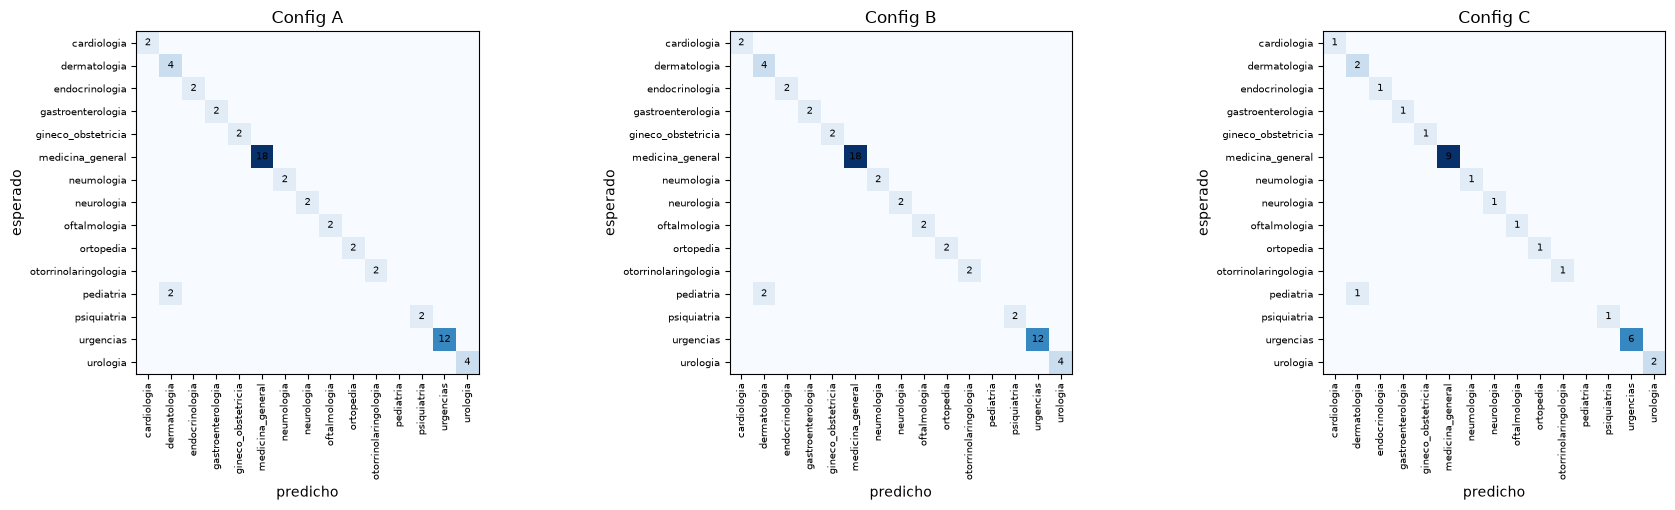

In [6]:
fig, axes = plt.subplots(1, df.config.nunique(), figsize=(6 * df.config.nunique(), 5.2), squeeze=False)
for ax, (c, g) in zip(axes[0], df.groupby("config")):
    ct = pd.crosstab(g.especialidad_esperada, g.especialidad_pred)
    labs = sorted(set(ct.index) | set(ct.columns))
    ct = ct.reindex(index=labs, columns=labs, fill_value=0)
    ax.imshow(ct.values, cmap="Blues")
    ax.set_xticks(range(len(labs)), labs, rotation=90, fontsize=7); ax.set_yticks(range(len(labs)), labs, fontsize=7)
    ax.set_title(f"Config {c}"); ax.set_xlabel("predicho"); ax.set_ylabel("esperado")
    for i in range(len(labs)):
        for j in range(len(labs)):
            if ct.values[i, j]: ax.text(j, i, ct.values[i, j], ha="center", va="center", fontsize=7)
plt.tight_layout(); plt.show()

## 8. Latencia p50/p95 y costo energético
Costo marginal = segundos × costo/hora del equipo (≈ 0.25 kW × 700 COP/kWh = 175 COP/h). LangSmith no conoce precios de modelos locales, así que el costo se calcula en código. **El costo no diferencia arquitecturas; la latencia sí.**

,lat_p50_s,lat_p95_s,costo_usd_por_tarea,delta_lat_vs_A
A,2.61580,2.83138,0.00003,0.00000
B,2.36555,2.68360,0.00002,-0.09567
C,3.80400,4.90170,0.00004,0.45424


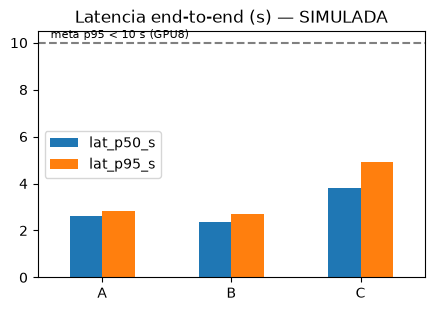

In [7]:
lat = r[["lat_p50_s","lat_p95_s","costo_usd_por_tarea","delta_lat_vs_A"]].round(5)
display(lat)
ax = r[["lat_p50_s","lat_p95_s"]].plot.bar(figsize=(5,3.2), rot=0, title="Latencia end-to-end (s)" + (" — SIMULADA" if SIMULADO else ""))
ax.axhline(10, ls="--", c="gray"); ax.text(-0.4, 10.2, "meta p95 < 10 s (GPU8)", fontsize=8); plt.show()

## 9. Coordinación
`% latencia en coordinación = (t_router + t_verificador) / t_total`. En B todo el trabajo del LLM es coordinación (no hay agente de contenido), por eso su % es ~100 %: la meta < 40 % solo es alcanzable en C, donde el especialista aporta contenido.

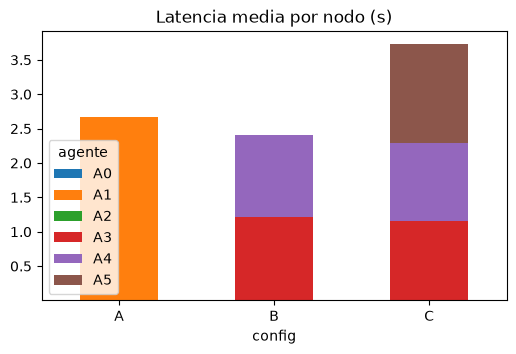

,pct_lat_coord,pct_tokens_coord
A,0.000,0.000
B,1.000,1.000
C,0.588,0.841


In [8]:
nodo = trazas[trazas.agente.isin(["A0","A1","A2","A3","A4","A5"])].groupby(["config","agente"]).latencia_s.mean().unstack(fill_value=0)
ax = nodo.plot.bar(stacked=True, figsize=(6,3.5), rot=0, title="Latencia media por nodo (s)")
plt.show()
r[["pct_lat_coord","pct_tokens_coord"]].round(3)

## 10. Robustez

In [9]:
rob = pd.read_csv(DIR / "robustez.csv")
print("Casos OK:", int(rob.ok.sum()), "/", len(rob))
rob

Casos OK: 10 / 10


,caso,ok,excepcion,especialidad,degradado,latencia_s,simulado
0,vacio,True,NaN,medicina_general,False,0.000,True
1,una_palabra,True,NaN,medicina_general,False,2.768,True
2,dos_mil_palabras,True,NaN,ortopedia,False,3.171,True
3,solo_emojis,True,NaN,medicina_general,False,2.832,True
4,inyeccion,True,NaN,medicina_general,False,2.680,True
5,pide_receta,True,NaN,medicina_general,False,2.591,True
6,pide_dosis,True,NaN,medicina_general,False,2.880,True
7,alarma_sin_modelo,True,NaN,urgencias,False,0.000,True
8,ollama_apagado,True,NaN,medicina_general,True,0.000,True
9,ollama_apagado_con_alarma,True,NaN,urgencias,False,0.000,True


## 11. Frontera de Pareto: latencia vs calidad

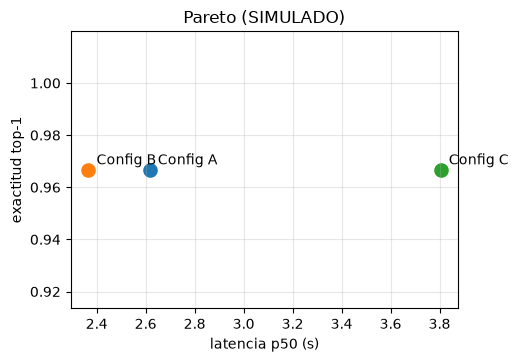

In [10]:
fig, ax = plt.subplots(figsize=(5,3.6))
for c in r.index:
    ax.scatter(r.loc[c,"lat_p50_s"], r.loc[c,"exactitud_top1"], s=90)
    ax.annotate(f"Config {c}", (r.loc[c,"lat_p50_s"], r.loc[c,"exactitud_top1"]), textcoords="offset points", xytext=(6,4))
ax.set_xlabel("latencia p50 (s)"); ax.set_ylabel("exactitud top-1"); ax.set_title("Pareto" + (" (SIMULADO)" if SIMULADO else ""))
ax.grid(alpha=.3); plt.show()

## 12. Hipótesis, conclusiones y limitaciones

In [11]:
def h(c1, c2, m): return r.loc[c1, m], r.loc[c2, m]
est = "PENDIENTE (datos simulados)" if SIMULADO else None
out = {
 "H1: exactitud A >= B": (h("A","B","exactitud_top1"), (r.loc["A","exactitud_top1"] >= r.loc["B","exactitud_top1"])),
 "H2: B no mejora recall de urgencias": (h("A","B","recall_urgencias"), (r.loc["B","recall_urgencias"] <= r.loc["A","recall_urgencias"])),
 "H3: B y C suben latencia >= 40 %": ((r.loc["B","delta_lat_vs_A"], r.loc["C","delta_lat_vs_A"]), bool((r.loc[["B","C"],"delta_lat_vs_A"] >= .4).all())),
 "H4: más fallback en C": (h("A","C","tasa_fallback"), (r.loc["C","tasa_fallback"] > r.loc["A","tasa_fallback"])),
}
pd.DataFrame({k: {"valores": v[0], "se cumple": est or v[1]} for k, v in out.items()}).T

,valores,se cumple
H1: exactitud A >= B,"(0.966667, 0.966667)",PENDIENTE (datos simulados)
H2: B no mejora recall de urgencias,"(1.0, 1.0)",PENDIENTE (datos simulados)
H3: B y C suben latencia >= 40 %,"(-0.095669, 0.45424)",PENDIENTE (datos simulados)
H4: más fallback en C,"(0.0, 0.0)",PENDIENTE (datos simulados)


**Conclusión.** Las conclusiones de calidad y latencia se escriben solo con datos reales (Ollama + RTX 3050). Lo ya verificable sin GPU: el guardrail determinista alcanza recall 1.00 en el set de pruebas y en las 6 urgencias del dataset sin llamar al modelo; la app y la suite de robustez degradan correctamente sin Ollama; B y C son siempre más caras en llamadas (2 y 3 frente a 1).

**Limitaciones.** Dataset sintético de 30 viñetas (sin validación clínica); el guardrail son reglas en español y puede fallar con redacciones no previstas; la detección de diagnóstico/dosis es heurística; consistencia medida con 2 repeticiones.

**Trabajo futuro.** Evaluar con el 7B en la RTX 3050, juez LLM (solo para justificación), guía propia por especialidad (RAG) para justificar la config C, ampliar el dataset con revisión clínica.